# NimbusPay ticket triage: fine-tuning Qwen2.5-3B-Instruct with LoRA

This notebook reproduces the final adapter (`adapter/`) and `predictions_test.jsonl` from scratch on a free Colab T4.
The baselines (Part B) and the controlled experiments (Part D) are slower to run. By default the notebook loads
their saved results from `results/`; set the flags below to `True` to re-run them. Their code is in this notebook.

**Layout expected in `WORKDIR` (Google Drive):** this repository checkout, plus the files from the candidate pack:
`data/train.jsonl`, `data/dev.jsonl`, `data/test_inputs.jsonl`, `score.py`.
The code lives in the repository modules:
`triage_rules.py` (rule checker from SCHEMA.md), `audit.py` (cleaning), `augment.py` (augmentation),
`train_lib.py` (training loop and inference).

| Section | Contents | T4 time |
|---|---|---|
| 0 | setup | 3 min |
| A | data audit + cleaning + augmentation (CPU) | 2 min |
| C | pipeline checks: chat template, loss mask, sequence length | 1 min |
| B | baselines (saved unless `RUN_BASELINES`) | ≈35 min |
| D | experiments (saved unless `RUN_EXPERIMENTS`) | ≈2.5 h |
| F | **final model: train, then dev score and test predictions** | ≈60 min |
| E | error analysis | 1 min |

## 0. Setup

In [1]:
import os, sys, json, re, random, collections, time, gc
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "transformers==5.22.2" "peft==0.21.2" "accelerate==1.15.0" bitsandbytes scikit-learn tabulate
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/nimbuspay-triage")
elif os.environ.get("WORKDIR"):          # Modal T4 container (modal_app.py), same pinned packages
    os.chdir(os.environ["WORKDIR"])
sys.path.insert(0, os.getcwd())

import torch, transformers, peft
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
for f in ["data/train.jsonl", "data/dev.jsonl", "data/test_inputs.jsonl", "score.py"]:
    assert os.path.exists(f), f"missing {f}: copy the candidate pack files into {os.getcwd()}"

RUN_BASELINES   = os.environ.get("RUN_BASELINES") == "1"     # Part B: re-run the baselines (else load results/)
RUN_EXPERIMENTS = os.environ.get("RUN_EXPERIMENTS") == "1"   # Part D: re-run the experiments (else load results/)
SMOKE = not torch.cuda.is_available()   # CPU dry-run of the whole notebook with a 0.5B model and tiny subsets
os.makedirs("results", exist_ok=True)

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.15.0+cu132 | transformers 5.22.2 | peft 0.21.2
GPU: NVIDIA A10


## A. Data audit

Method. I wrote an independent **rule checker** (`triage_rules.py`) from SCHEMA.md. It parses each ticket and
re-derives every field except `category`, then compares the result with the stored label. Before trusting it on
train I checked it on the clean dev set (A.1), where it should agree with every label. Disagreements on train
were then grouped and inspected by hand. Category has no rule-based answer, so I checked it separately with
cross-validated confident learning (A.6).

In [2]:
from triage_rules import *
from audit import reference_label, norm_body
train_raw, dev, test = load("data/train.jsonl"), load("data/dev.jsonl"), load("data/test_inputs.jsonl")
print(len(train_raw), len(dev), len(test))

def agreement(rows):
    tot, ok, bad = collections.Counter(), collections.Counter(), collections.defaultdict(list)
    for r in rows:
        try: g = json.loads(r["messages"][2]["content"])
        except json.JSONDecodeError: continue
        if "priority" not in g: continue
        ref = reference_label(g["category"], signals(r["messages"][1]["content"]))
        for k in KEYS[1:]:
            tot[k] += 1; ok[k] += ref[k] == g[k]
            if ref[k] != g[k]: bad[k].append(r["id"])
    return {k: f"{ok[k]}/{tot[k]}" for k in tot}, bad

print("A.1 checker vs DEV labels :", agreement(dev)[0])
agr_train, bad_train = agreement(train_raw)
print("    checker vs TRAIN labels:", agr_train)

1445 200 400
A.1 checker vs DEV labels : {'priority': '200/200', 'amount_paise': '200/200', 'txn_date': '200/200', 'txn_id': '200/200', 'channel': '200/200', 'language': '200/200', 'needs_human': '200/200'}


    checker vs TRAIN labels: {'priority': '1288/1350', 'amount_paise': '1318/1350', 'txn_date': '1346/1350', 'txn_id': '1326/1350', 'channel': '1346/1350', 'language': '1345/1350', 'needs_human': '1348/1350'}


### A.2 Structural problems: label JSON that doesn't parse, and labels from the old spec

In [3]:
invalid, old = [], []
for r in train_raw:
    a = r["messages"][2]["content"]
    try: o = json.loads(a)
    except json.JSONDecodeError: invalid.append(r); continue
    if list(o) != KEYS: old.append((r, o))
print(f"{len(invalid)} labels are truncated JSON, e.g.:")
for r in invalid[:3]: print("   ", r["id"], repr(r["messages"][2]["content"]))
print(f"\n{len(old)} labels use a different key set:", collections.Counter(tuple(o) for _, o in old).most_common())
print("old 'prio' value vs priority recomputed with the v2 rules:",
      collections.Counter((o["prio"], reference_label(o["category"], signals(r["messages"][1]["content"]))["priority"]) for r, o in old))
print("txn_date formats in those rows:", collections.Counter(re.sub(r"\d", "9", o["txn_date"] or "null") for _, o in old))

25 labels are truncated JSON, e.g.:
    tr-00060 '{"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "t'
    tr-00095 '{"category": "other", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "c'
    tr-00125 '{"category": "payment_failed", "priority": "P3", "amount_paise": 392500, "txn_date": "2026-08-12", "t'

70 labels use a different key set: [(('category', 'prio', 'amount_paise', 'txn_date', 'txn_id', 'channel', 'language', 'needs_human'), 70)]
old 'prio' value vs priority recomputed with the v2 rules: Counter({('low', 'P3'): 44, ('medium', 'P2'): 15, ('high', 'P1'): 11})
txn_date formats in those rows: Counter({'null': 40, '99/99/9999': 30})


### A.3 Junk tickets, duplicates, and leakage into dev/test

In [4]:
junk = [r for r in train_raw if len(parse_ticket(r["messages"][1]["content"])[2].strip()) < 25
        and re.fullmatch(r"(?i)[\s\d]*((test|asdf)[\s\d]*)*", parse_ticket(r["messages"][1]["content"])[2].strip())]
print(f"{len(junk)} junk tickets with full labels, e.g.:")
for r in junk[:4]: print("   ", r["id"], repr(parse_ticket(r["messages"][1]["content"])[2]), "->", r["messages"][2]["content"][:90])

exact = collections.Counter(r["messages"][1]["content"] for r in train_raw)
print("\nexact duplicate tickets (extra copies):", sum(v - 1 for v in exact.values() if v > 1))
near = collections.Counter(r["messages"][1]["content"].split("\n\n")[0] + norm_body(r["messages"][1]["content"]) for r in train_raw)
print("duplicates after collapsing whitespace / trailing 'Thx' (extra copies):", sum(v - 1 for v in near.values() if v > 1))

dev_exact = {r["messages"][1]["content"] for r in dev}; dev_norm = {norm_body(r["messages"][1]["content"]) for r in dev}
test_norm = {norm_body(r["messages"][1]["content"]) for r in test}
print("\ntrain rows identical to a dev ticket:", sum(r["messages"][1]["content"] in dev_exact for r in train_raw),
      "| after normalisation:", sum(norm_body(r["messages"][1]["content"]) in dev_norm for r in train_raw),
      "| identical to a test ticket:", sum(norm_body(r["messages"][1]["content"]) in test_norm for r in train_raw))

10 junk tickets with full labels, e.g.:
    tr-00034 'test test 123' -> {"category": "refund", "priority": "P2", "amount_paise": 1474500, "txn_date": "2026-08-20"
    tr-00164 'test' -> {"category": "offers", "priority": "P3", "amount_paise": 6500, "txn_date": null, "txn_id":
    tr-00318 '' -> {"category": "kyc", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": nu
    tr-00555 'test test 123' -> {"category": "payment_failed", "priority": "P2", "amount_paise": 1913400, "txn_date": "202

exact duplicate tickets (extra copies): 60
duplicates after collapsing whitespace / trailing 'Thx' (extra copies): 91

train rows identical to a dev ticket: 30 | after normalisation: 45 | identical to a test ticket: 0


### A.4 Field-level label noise found by the checker (each group inspected by hand)

In [5]:
rows_by_id = {r["id"]: r for r in train_raw}
def show(ids, field, n=4):
    for i in ids[:n]:
        r = rows_by_id[i]; g = json.loads(r["messages"][2]["content"]); s = signals(r["messages"][1]["content"])
        ref = reference_label(g["category"], s)
        print(f"  {i} [{g['category']}] label {field}={g[field]!r}  checker={ref[field]!r}\n     {s['text'].strip()[:200]!r}")
junk_ids = {r["id"] for r in junk}
for field in ["priority", "amount_paise", "txn_id", "needs_human", "txn_date", "channel", "language"]:
    ids = [i for i in bad_train[field] if i not in junk_ids]
    print(f"\n{field}: {len(ids)} disagreements (junk rows excluded)"); show(ids, field)


priority: 60 disagreements (junk rows excluded)
  tr-00013 [kyc] label priority='P1'  checker='P3'
     'Hi,\nKYC mein address update karna hai. Android app use kar raha hoon. Bank ref 782509120860 hai. Pehle bhi complaint kar chuka hoon.'
  tr-00018 [offers] label priority='P1'  checker='P3'
     'Dear NimbusPay support,\nReferral bonus was not received after my friend signed up. Mode: UPI. My phone is a OnePlus Nord. The transaction amount is Rs. 250. Thanks.'
  tr-00023 [kyc] label priority='P1'  checker='P3'
     'URGENT!! How can you assist on verifying my identity? I am on the iOS app. Please look into it.'
  tr-00045 [fraud] label priority='P3'  checker='P1'
     'I AM MISSING CASH FROM MY BANK ACCOUNT ACCORDING TO MY APP. The amount was INR 11,594. I am on the iOS app. Waiting for your reply.'

amount_paise: 25 disagreements (junk rows excluded)
  tr-00073 [payment_failed] label amount_paise=168787  checker=16878725
     "URGENT!!\nI'm sure I have enough money so why didn't th

What the groups contain (I read every row):
* **priority**: random flips, e.g. a ₹495 refund marked P1, fraud marked P3, a legal threat left at P3. `needs_human` in the same rows is consistent with the *correct* priority, so only the priority value was corrupted.
* **amount_paise**: the amount stored in rupees instead of paise (₹674 → `674`), or `k`/`lakh` handled wrongly (34.3k → `34300`).
* **txn_id**: not normalised (`np 81633 47892`, `NP-…`, lower case).
* **needs_human**: no disagreement once the corrected priority is used.
* **txn_date / channel / language**: only junk rows and one checker false positive ("Srcatch card" typo) disagree, so nothing to fix.

### A.5 Run the cleaning (`audit.py`) and write `cleaning_log.csv`

In [6]:
!{sys.executable} audit.py
import pandas as pd
log = pd.read_csv("cleaning_log.csv")
print(log.action.value_counts().to_string())
log["kind"] = log.reason.str.extract(r"^(junk|same ticket as a dev|duplicate|label JSON truncated|old-spec|txn_date|txn_id|amount_paise|priority|needs_human)")[0]
print(log.groupby(["action", "kind"]).size().to_string())

UNRESOLVED tr-00050 channel: label=None checker='card'


drop_dev_leak            45
drop_duplicate           91
drop_junk                10
fix_amount               25
fix_date_format          30
fix_prio_key             70
fix_priority             60
fix_truncated            25
fix_txn_id_format        20
rows_dropped             146
rows_fixed               200
rows_in                  1445
rows_out                 1299
unresolved_channel       1


action
fix     200
drop    146
action  kind                
drop    duplicate               91
        junk                    10
        same ticket as a dev    45
fix     amount_paise            25
        label JSON truncated    25
        old-spec                70
        priority                60
        txn_id                  20


### A.6 Category noise: cross-validated confident learning
I train a TF-IDF (word + character n-gram) logistic regression with 10-fold cross-validation on the cleaned train
rows, then read every row whose out-of-fold prediction disagrees with its label.

In [7]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline, make_union
clean = load("data/train_clean.jsonl")
X = [re.sub(r"\d", "0", parse_ticket(r["messages"][1]["content"])[2]) for r in clean]
y = np.array([json.loads(r["messages"][2]["content"])["category"] for r in clean])
clf = make_pipeline(make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                               TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
                    LogisticRegression(C=10, max_iter=3000))
P = cross_val_predict(clf, X, y, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")
classes = sorted(set(y)); pred = np.array(classes)[P.argmax(1)]
print(f"out-of-fold accuracy {np.mean(pred == y):.3f}; {np.sum(pred != y)} disagreements to review")
for i in np.argsort(-P.max(1)):
    if pred[i] != y[i]:
        print(f"  {clean[i]['id']} label={y[i]:15} oof={pred[i]:15} p={P[i].max():.2f} | {X[i].strip()[:110]}")

out-of-fold accuracy 0.977; 30 disagreements to review
  tr-00257 label=fraud           oof=refund          p=0.72 | Good morning,
I see a payment on my statement for a place I didn't make a purchase at. It was from the NimbusP
  tr-01286 label=account_access  oof=other           p=0.71 | [IVR transcript] Hi team, My card's frozen, what can I do? Please look into it.
  tr-00729 label=refund          oof=payment_failed  p=0.69 | Hi, My card was declined but it shows as multiple charges? Rs. 0000 is the amount. It took place today.
  tr-01159 label=other           oof=account_access  p=0.67 | Hello,
Do i have to wait to get the pin or can i set up a pin. App version is 0.0.0. Please help.
  tr-01333 label=fraud           oof=refund          p=0.66 | Hello,
I have a charge I did not make. Transaction ID np0000000000. It took place today. Amount: ₹00,000 It wa
  tr-01357 label=fraud           oof=payment_failed  p=0.63 | [IVR transcript] Hi, Payment I did not make. Dated Jun 0. Total ₹000.

Reading these, the classifier is wrong in almost every case (for example "I don't recognise a charge on my card"
is correctly labelled `fraud`). A few are genuinely ambiguous ("My card's frozen" → `account_access`, "can't log in
but my info is correct" → `kyc`). None is clearly wrong under SCHEMA.md, so **I change no categories**. Random
category flips at a rate like the priority noise (≈4%) would show up here as ≈50 confident disagreements, and they don't.

### A.7 Train vs test: phrasings that only appear in test
I compared surface patterns across the splits using the *unlabelled* test inputs.
Every pattern below is covered by a rule in SCHEMA.md.

In [8]:
pats = {"quoted earlier e-mail": r"^>", "'last month on the Nth'": r"last month on the", "'the Nth of this month'": r"of this month",
        "spaced id 'N P 1234 567 890'": r"N P \d", "'The sum involved is'": r"sum involved", "'Poore ... ka mamla'": r"Poore",
        "order number": r"Order number", "fee / convenience fee": r"\bfee", "k amounts": r"\d(\.\d)?k\b", "lakh": r"lakh",
        "legal threat": r"RBI|ombudsman|consumer court|lawyer|legal", "relative Hinglish date (kal/parso/din pehle)": r"\bkal\b|\bparso\b|din pehle"}
def frac(rows, rx): return np.mean([bool(re.search(rx, r["messages"][1]["content"], re.M)) for r in rows])
print(pd.DataFrame({k: {"train": frac(train_raw, v), "dev": frac(dev, v), "test": frac(test, v)} for k, v in pats.items()}).T.map(lambda x: f"{x:.1%}").to_string())

                                             train   dev  test
quoted earlier e-mail                         2.8%  1.5%  2.8%
'last month on the Nth'                       0.0%  0.0%  1.8%
'the Nth of this month'                       0.0%  0.0%  3.2%
spaced id 'N P 1234 567 890'                  0.0%  0.0%  3.0%
'The sum involved is'                         0.0%  0.0%  3.8%
'Poore ... ka mamla'                          0.0%  0.0%  5.5%
order number                                  0.0%  0.0%  6.5%
fee / convenience fee                         0.8%  0.5%  3.2%
k amounts                                     6.2%  3.0%  5.5%
lakh                                          1.9%  2.0%  2.2%
legal threat                                  4.8%  3.5%  5.2%
relative Hinglish date (kal/parso/din pehle)  2.8%  2.5%  5.8%


### A.8 Augmentation (Part D experiment 4)
`augment.py` creates 700 extra rows from cleaned train tickets. Each one applies 1–3 edits whose effect on the
label is fully set by SCHEMA.md:
- id formats with spaces, hyphens or symbols
- relative and year-less dates ("last month on the 18th")
- reworded claim amounts (`Rs.X/-`, `k`, `lakh`, "sum involved")
- amounts moved across the ₹5k/₹50k thresholds
- distractor fee, balance, limit, order-number and bank-ref sentences
- quoted earlier e-mails
- other ways of stating the channel, a legal threat or a repeat contact

Every generated row is re-labelled by the independent checker and dropped if the two labels disagree.

In [9]:
!{sys.executable} augment.py --n 700 --seed 0
aug = load("data/train_aug.jsonl")
for r in random.Random(1).sample(aug, 3):
    print(r["ops"], "\n ", r["messages"][1]["content"].replace("\n", " | ")[:300], "\n  ->", r["messages"][2]["content"], "\n")

wrote 700 rows to data/train_aug.jsonl; rejected by cross-check: 75; op counts: {'ids': 63, 'date': 163, 'distract': 314, 'thresh': 101, 'legal': 102, 'amount': 116, 'quote': 33, 'repeat': 116, 'channel': 26}


['ids'] 
  Received: 2026-09-05 (Sat) | Source: app-chat |  | URGENT!! My card is not working at stores. It took place on 05/09/2026. It was for 33213 rupees. Payment ref: np.7942590892. I am using app version 6.0.0. Please look into it. 
  -> {"category": "payment_failed", "priority": "P2", "amount_paise": 3321300, "txn_date": "2026-09-05", "txn_id": "NP7942590892", "channel": "card", "language": "en", "needs_human": false} 

['legal'] 
  Received: 2026-06-22 (Mon) | Source: app-chat |  | Good morning, I didn't get cash from an ATM, but according to the app a transaction was made when i didn't make it. Rs 10,007.50 is the amount. Expect a legal notice from my lawyer. Thanks. 
  -> {"category": "fraud", "priority": "P1", "amount_paise": 1000750, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": true} 

['distract'] 
  Received: 2026-07-05 (Sun) | Source: email |  | Subject: Problem with NimbusPay |  | Namaste, | Shopping ka payment declnie ho gaya leki

For experiment D.1 ("raw" data) I use `train.jsonl` exactly as shipped **minus the 45 rows that duplicate dev
tickets**. Leaving those in would mean training on dev, which the rules forbid and which would inflate the dev score.

In [10]:
leak = set(log[log.reason.str.startswith("same ticket as a dev")].id)
with open("data/train_raw_noleak.jsonl", "w") as f:
    for r in train_raw:
        if r["id"] not in leak: f.write(json.dumps(r, ensure_ascii=False) + "\n")
print(len(train_raw) - len(leak), "raw rows written (", len(leak), "dev-leak rows removed )")

1400 raw rows written ( 45 dev-leak rows removed )


## C. Training pipeline (code in `train_lib.py`)
**Model.** `Qwen/Qwen2.5-3B-Instruct` (3.09B parameters, ungated, Apache-style weights). Its chat template has a
real `system` role, so the fixed system prompt is used as-is. It is strong on Hindi/Hinglish and number handling
for its size, and it fits a T4 in fp16 for both 16-bit LoRA and 4-bit QLoRA.

**Stack.** HF `transformers` + `peft`, with a small hand-written PyTorch training loop rather than `Trainer`.
The loss masking, gradient-accumulation normalisation and fp16 handling are then explicit and don't depend on a
library version.

Checks below: (1) training tokens = inference tokens + answer; (2) loss only on the answer and `<|im_end|>`; (3) sequence length.

In [11]:
from train_lib import *
BASE = "Qwen/Qwen2.5-0.5B-Instruct" if SMOKE else "Qwen/Qwen2.5-3B-Instruct"
tok = load_tokenizer(BASE)
ex = encode_example(tok, clean[0]["messages"], 4096)
n_prompt = sum(1 for x in ex["labels"] if x == -100)
inference_ids = tok(prompt_text(tok, FIXED_SYSTEM, clean[0]["messages"][1]["content"]), add_special_tokens=False).input_ids
print("prompt ids identical to inference ids:", ex["input_ids"][:n_prompt] == inference_ids)
print("---- unmasked (trained) tokens:\n" + tok.decode([t for t in ex["labels"] if t != -100]))
print("---- last 25 prompt tokens (masked):\n" + tok.decode(ex["input_ids"][n_prompt - 25:n_prompt]))

prompt ids identical to inference ids: True
---- unmasked (trained) tokens:
{"category": "payment_failed", "priority": "P3", "amount_paise": 470000, "txn_date": "2026-07-25", "txn_id": "NP1599046332", "channel": "netbanking", "language": "en", "needs_human": false}<|im_end|>
---- last 25 prompt tokens (masked):
 txn id is NP1599046332. Waiting for your reply.<|im_end|>
<|im_start|>assistant



In [12]:
def lens(rows, answer=True):
    out = []
    for r in rows:
        p = len(tok(prompt_text(tok, r["messages"][0]["content"], r["messages"][1]["content"]), add_special_tokens=False).input_ids)
        a = len(tok(r["messages"][2]["content"]).input_ids) + 1 if answer and len(r["messages"]) > 2 else 0
        out.append(p + a)
    return np.array(out)
L = {"train_clean": lens(clean), "train_aug": lens(aug), "dev": lens(dev), "test (prompt only)": lens(test, False)}
print(pd.DataFrame({k: {"p50": np.median(v), "p95": np.percentile(v, 95), "p99": np.percentile(v, 99), "max": v.max(),
                        ">512": int((v > 512).sum())} for k, v in L.items()}).T.to_string())
print("answer tokens max:", max(len(tok(r["messages"][2]["content"]).input_ids) for r in clean + dev))

                      p50     p95      p99     max  >512
train_clean         167.0  224.00  1817.40  2214.0  36.0
train_aug           188.0  283.25  1788.04  2340.0  14.0
dev                 172.5  222.00  1515.65  2180.0   3.0
test (prompt only)  108.0  151.05  1827.22  2089.0  11.0
answer tokens max: 83


The distribution is **bimodal**. 95% of sequences are under about 230 tokens, but the e-mails with long quoted
support threads run to 2.1–2.3k tokens, in train and in test. Truncating them would cut off the answer, which is
the only part the loss sees. So `max_len = 2400` keeps every row whole. Two things keep this cheap:
- micro-batches are **length-grouped**, so short rows are not padded to 2.4k;
- logits are computed **only at answer positions**. A full `[4 × 2400 × 152k]` fp32 logit tensor would be about 5.8 GB.

Answers are at most 84 tokens, well within `max_new_tokens=200`.

**Main settings and why:**

| setting | value | reason |
|---|---|---|
| LoRA targets | all 7 linear projections | the task needs new behaviour (format + rules), not only attention re-weighting |
| rank / alpha | 16 / 32 | 29.9M trainable params (< 50M limit; r=32 would be 59.9M); alpha = 2r is the usual scale |
| dropout | 0.05 | small dataset, mild regularisation |
| lr | 2e-4, cosine, 5% warm-up | standard LoRA rate; cosine decays to 0 so the last steps are stable |
| effective batch | 16 (4 × 4 accumulation) | ≈80 optimizer steps per epoch on ~1.3k rows |
| loss normalisation | sum of answer-token CE ÷ answer tokens in the whole optimizer step | every answer token weighs the same across micro-batches |
| epochs | 2 | the run-to-run comparison is in Part D |
| precision | fp16 autocast + GradScaler, LoRA weights in fp32 | the T4 has no bf16 |
| grad checkpointing | on (non-reentrant) | needed for the 2.3k-token rows |

## B. Baselines (dev, `score.py`)
1. base model, fixed system prompt, no fine-tuning;
2. base model with SCHEMA.md appended to the system prompt (allowed only here, as a reference point).

Decoding is greedy with `max_new_tokens=200`. Baselines and experiments use left-padded batches of 8 to save GPU
time; the final model is scored with batch size 1, exactly as the graders run it. The "lenient" column (first `{…}`
block in the output) is for diagnosis only: it separates format failures from content failures.

In [13]:
import experiments as X
X.BASE = BASE
DEV_EVAL = dev[:6] if SMOKE else dev
for name in X.BASELINES:
    path = f"results/{name}.json"
    if RUN_BASELINES or (SMOKE and not os.path.exists(path)):
        X.run_baseline(name, DEV_EVAL, base=BASE)
    if os.path.exists(path):
        res = json.load(open(path))
        print(f"{name:26} valid={res['json_valid']:.1%} exact={res['exact_match']:.1%} fields={res['mean_field_acc']:.1%} "
              f"| lenient: exact={res['lenient']['exact_match']:.1%} fields={res['lenient']['mean_field_acc']:.1%}")
        print("   per field:", {k: round(v, 3) for k, v in res["fields"].items()})
        print("   sample output:", repr(load(f"results/{name}_dev_preds.jsonl")[0]["output"][:200]))

baseline_fixed_prompt      valid=0.5% exact=0.0% fields=0.0% | lenient: exact=0.0% fields=0.3%
   per field: {'category': 0.0, 'priority': 0.0, 'amount_paise': 0.0, 'txn_date': 0.0, 'txn_id': 0.0, 'channel': 0.0, 'language': 0.0, 'needs_human': 0.0}
   sample output: '```json\n{\n  "id": "ticket-12345",\n  "created_at": "2026-08-28T09:00:00Z",\n  "updated_at": "2026-08-28T09:00:00Z",\n  "status": "open",\n  "type": "support",\n  "priority": "normal",\n  "subject": "How to '
baseline_rules_in_prompt   valid=100.0% exact=26.0% fields=82.0% | lenient: exact=26.0% fields=82.0%
   per field: {'category': 0.865, 'priority': 0.495, 'amount_paise': 0.865, 'txn_date': 0.865, 'txn_id': 0.915, 'channel': 0.895, 'language': 0.91, 'needs_human': 0.75}
   sample output: '{"category": "other", "priority": "P3", "amount_paise": null, "txn_date": null, "txn_id": null, "channel": null, "language": "en", "needs_human": true}'


## D. Controlled experiments (one change at a time against `ref`)
`ref` = cleaned data, 16-bit LoRA, r=16, lr 2e-4, 2 epochs.

| run | change vs `ref` |
|---|---|
| `raw` | training data = shipped `train.jsonl` (minus dev leakage) instead of the cleaned file |
| `qlora` | base model loaded in 4-bit NF4 (QLoRA) instead of fp16 |
| `ep3` | 3 epochs instead of 2 |
| `aug` | cleaned data **+ 700 rule-grounded augmented rows** (my own idea) |

With n=200, one dev row is 0.5 points, so small differences are noise. The table includes an exact McNemar test on
per-row exact match against `ref`.

In [14]:
from dataclasses import replace
EXPERIMENTS = {k: replace(c, base_model=BASE) for k, c in X.EXPERIMENTS.items()}
for k, c in EXPERIMENTS.items(): print(f"{k:6}", c)
if SMOKE:   # tiny CPU dry run: 24 rows, 1 epoch, 4-bit skipped (bitsandbytes needs CUDA)
    for f in ["data/train_clean.jsonl", "data/train_raw_noleak.jsonl", "data/train_aug.jsonl"]:
        open(f.replace("data/", "data/smoke_"), "w").writelines(open(f).readlines()[:24])
    EXPERIMENTS = {k: replace(c, train_files=[f.replace("data/", "data/smoke_") for f in c.train_files], epochs=1)
                   for k, c in list(EXPERIMENTS.items())[:2]}
for name, cfg in EXPERIMENTS.items():
    if RUN_EXPERIMENTS or (SMOKE and not os.path.exists(f"results/{name}.json")):
        X.run_experiment(cfg, DEV_EVAL)

ref    Cfg(name='ref', base_model='Qwen/Qwen2.5-3B-Instruct', train_files=['data/train_clean.jsonl'], load_4bit=False, r=16, alpha=32, dropout=0.05, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], lr=0.0002, epochs=2, micro_bs=4, grad_accum=4, warmup_frac=0.05, weight_decay=0.0, max_len=2400, seed=42, out_root='runs')
raw    Cfg(name='raw', base_model='Qwen/Qwen2.5-3B-Instruct', train_files=['data/train_raw_noleak.jsonl'], load_4bit=False, r=16, alpha=32, dropout=0.05, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], lr=0.0002, epochs=2, micro_bs=4, grad_accum=4, warmup_frac=0.05, weight_decay=0.0, max_len=2400, seed=42, out_root='runs')
qlora  Cfg(name='qlora', base_model='Qwen/Qwen2.5-3B-Instruct', train_files=['data/train_clean.jsonl'], load_4bit=True, r=16, alpha=32, dropout=0.05, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], lr=0.0002, epochs=2

In [15]:
CHANGE = {"ref": "reference (clean, 16-bit LoRA, r16, lr 2e-4, 2 ep)", "raw": "data: raw train (minus dev leakage)",
          "qlora": "4-bit QLoRA base", "ep3": "epochs 2 → 3", "aug": "+ 700 augmented rows", "final": "final (see F)"}
def experiment_table():
    table = []
    ref_ok = X.exact_ids("ref", DEV_EVAL) if os.path.exists("results/ref_dev_preds.jsonl") else None
    for name in ["ref", "raw", "qlora", "ep3", "aug", "final"]:
        p = f"results/{name}.json"
        if not os.path.exists(p): continue
        r = json.load(open(p))
        table.append({"run": name, "what changed": CHANGE[name], "dev exact": f"{r['exact_match']:.1%}",
                      "dev mean field acc": f"{r['mean_field_acc']:.1%}", "json valid": f"{r['json_valid']:.1%}",
                      "peak GPU mem (GB)": r.get("peak_gpu_mem_gb"), "train min": r.get("train_minutes"),
                      "McNemar p vs ref": "" if name == "ref" or ref_ok is None else f"{X.mcnemar(ref_ok, X.exact_ids(name, DEV_EVAL)):.3f}"})
    print(pd.DataFrame(table).to_markdown(index=False))
    if table:
        print("\nper-field dev accuracy:")
        print(pd.DataFrame({t["run"]: json.load(open(f"results/{t['run']}.json"))["fields"] for t in table}).map(lambda x: f"{x:.1%}").to_string())
experiment_table()

| run   | what changed                                       | dev exact   | dev mean field acc   | json valid   |   peak GPU mem (GB) |   train min |   McNemar p vs ref |
|:------|:---------------------------------------------------|:------------|:---------------------|:-------------|--------------------:|------------:|-------------------:|
| ref   | reference (clean, 16-bit LoRA, r16, lr 2e-4, 2 ep) | 90.5%       | 98.2%                | 100.0%       |                9.95 |       15.6  |                    |
| raw   | data: raw train (minus dev leakage)                | 87.0%       | 97.6%                | 100.0%       |                9.95 |       16.34 |              0.167 |
| qlora | 4-bit QLoRA base                                   | 89.5%       | 98.1%                | 100.0%       |                8.28 |       20.14 |              0.804 |
| ep3   | epochs 2 → 3                                       | 92.0%       | 98.2%                | 100.0%       |                9.95 |    

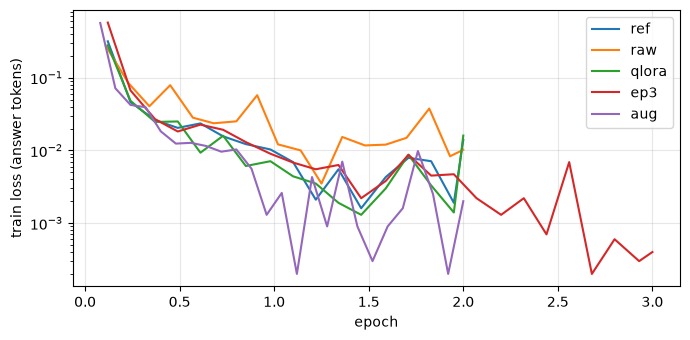

In [16]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in ["ref", "raw", "qlora", "ep3", "aug", "final"]:
    p = f"results/{name}.json"
    if os.path.exists(p) and json.load(open(p)).get("log"):
        lg = json.load(open(p))["log"]; ax.plot([x["epoch"] for x in lg], [x["loss"] for x in lg], label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("train loss (answer tokens)"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## F. Final model (always runs): train, then predict dev and test with batch size 1
Final configuration = `ref` + the changes that helped in Part D. `FINAL` is defined in `experiments.py`.

In [17]:
FINAL = replace(X.FINAL, base_model=BASE)
if SMOKE: FINAL = replace(FINAL, train_files=["data/smoke_train_clean.jsonl", "data/smoke_train_aug.jsonl"], epochs=1)
print(FINAL)
final_meta = train(FINAL)

Cfg(name='final', base_model='Qwen/Qwen2.5-3B-Instruct', train_files=['data/train_clean.jsonl', 'data/train_aug.jsonl'], load_4bit=False, r=16, alpha=32, dropout=0.05, target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], lr=0.0002, epochs=2, micro_bs=4, grad_accum=4, warmup_frac=0.05, weight_decay=0.0, max_len=2400, seed=42, out_root='runs')


[final] 1999 training sequences (0 over max_len=2400 dropped)


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/434 [00:00<04:45,  1.52it/s]

Loading weights:  37%|███▋      | 161/434 [00:00<00:00, 274.72it/s]

Loading weights:  55%|█████▍    | 238/434 [00:01<00:00, 285.62it/s]

... (28 outputs left out)

{'step': 230, 'epoch': 1.84, 'loss': 0.0015, 'grad_norm': 0.038, 'lr': 3.4645911347961357e-06, 'elapsed_min': 11.66}


{'step': 240, 'epoch': 1.92, 'loss': 0.0003, 'grad_norm': 0.011, 'lr': 8.699316894203224e-07, 'elapsed_min': 12.18}


{'step': 250, 'epoch': 2.0, 'loss': 0.0032, 'grad_norm': 0.094, 'lr': 0.0, 'elapsed_min': 12.59}


[final] done in 12.6 min, peak GPU memory 10.16 GB


In [18]:
import shutil
ADAPTER = os.path.join(FINAL.out_dir, "adapter")
tok, model = load_for_inference(FINAL.base_model, ADAPTER, FINAL.load_4bit)
dev_preds = generate(tok, model, DEV_EVAL, batch_size=1)
write_preds(dev_preds, "results/final_dev_preds.jsonl")
final_res = X.summarize("final", DEV_EVAL, dev_preds, {k: final_meta[k] for k in X.META_KEYS})
json.dump(final_res, open("results/final.json", "w"), indent=1)
!{sys.executable} score.py --gold data/dev.jsonl --pred results/final_dev_preds.jsonl
experiment_table()

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/434 [00:00<04:09,  1.74it/s]

Loading weights:  29%|██▊       | 124/434 [00:00<00:01, 243.41it/s]

Loading weights:  44%|████▍     | 193/434 [00:00<00:00, 248.27it/s]

Loading weights:  56%|█████▌    | 242/434 [00:01<00:00, 253.11it/s]

Loading weights:  65%|██████▌   | 283/434 [00:01<00:00, 239.76it/s]

... (7 outputs left out)

  101/200  6.1 min


  151/200  9.1 min


group                            n   valid   exact  fields
all                            200  100.0%   92.5%   98.6%
category=account_access         19  100.0%  100.0%  100.0%
category=fraud                  15  100.0%   80.0%   95.8%
category=kyc                    24  100.0%  100.0%  100.0%
category=offers                 18  100.0%  100.0%  100.0%
category=other                  16  100.0%  100.0%  100.0%
category=payment_failed         53  100.0%   90.6%   98.3%
category=refund                 55  100.0%   87.3%   97.5%

per-field accuracy (all rows)
  category        98.5%
  priority        95.0%
  amount_paise   100.0%
  txn_date        98.5%
  txn_id          99.5%
  channel        100.0%
  language       100.0%
  needs_human     97.0%


| run   | what changed                                       | dev exact   | dev mean field acc   | json valid   |   peak GPU mem (GB) |   train min |   McNemar p vs ref |
|:------|:---------------------------------------------------|:------------|:---------------------|:-------------|--------------------:|------------:|-------------------:|
| ref   | reference (clean, 16-bit LoRA, r16, lr 2e-4, 2 ep) | 90.5%       | 98.2%                | 100.0%       |                9.95 |       15.6  |                    |
| raw   | data: raw train (minus dev leakage)                | 87.0%       | 97.6%                | 100.0%       |                9.95 |       16.34 |              0.167 |
| qlora | 4-bit QLoRA base                                   | 89.5%       | 98.1%                | 100.0%       |                8.28 |       20.14 |              0.804 |
| ep3   | epochs 2 → 3                                       | 92.0%       | 98.2%                | 100.0%       |                9.95 |    

In [19]:
TEST_EVAL = test[:4] if SMOKE else test
test_preds = generate(tok, model, TEST_EVAL, batch_size=1)
write_preds(test_preds, "predictions_test.jsonl")
shutil.rmtree("adapter", ignore_errors=True); shutil.copytree(ADAPTER, "adapter")
print(len(test_preds), "test predictions written;", "valid JSON:", np.mean([lenient_parse(p["output"]) is not None and p["output"].startswith("{") for p in test_preds]))
print("adapter/:", os.listdir("adapter"))

  1/400  0.1 min


  51/400  3.1 min


  101/400  6.0 min


  151/400  9.0 min


  201/400  11.8 min


  251/400  14.8 min


  301/400  18.0 min


  351/400  20.8 min


400 test predictions written; valid JSON: 1.0
adapter/: ['README.md', 'adapter_model.safetensors', 'adapter_config.json']


Reproducibility check: reload from `adapter/` in a fresh model, as the graders will, and regenerate a random sample of test rows.

In [20]:
X.free(model); del model
tok, model = load_for_inference(FINAL.base_model, "adapter", FINAL.load_4bit)
sample = random.Random(7).sample(TEST_EVAL, min(10, len(TEST_EVAL)))
again = generate(tok, model, sample, batch_size=1, progress=0)
saved = {p["id"]: p["output"] for p in load("predictions_test.jsonl")}
print("identical:", sum(saved[p["id"]] == p["output"] for p in again), "/", len(again))

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/434 [00:00<03:59,  1.81it/s]

Loading weights:  29%|██▊       | 124/434 [00:00<00:01, 242.03it/s]

Loading weights:  42%|████▏     | 183/434 [00:00<00:00, 251.66it/s]

Loading weights:  52%|█████▏    | 227/434 [00:01<00:00, 252.41it/s]

Loading weights:  61%|██████    | 264/434 [00:01<00:00, 262.60it/s]

... (3 outputs left out)

Loading weights:  89%|████████▉ | 388/434 [00:01<00:00, 237.97it/s]

Loading weights:  95%|█████████▌| 414/434 [00:01<00:00, 233.97it/s]

Loading weights: 100%|██████████| 434/434 [00:01<00:00, 228.53it/s]

identical: 10 / 10


Decoding robustness: Qwen's shipped `generation_config` has `repetition_penalty=1.05`. A plain
`model.generate(..., do_sample=False)` keeps it, and that is what the predictions above use. Below I measure, on a
100-row test sample, how many outputs would change if a grader turned it off (`repetition_penalty=1.0`).

In [21]:
print("generation_config:", {k: getattr(model.generation_config, k, None) for k in ["do_sample", "temperature", "top_p", "top_k", "repetition_penalty"]})
ROBUST = TEST_EVAL[:100]   # a 100-row sample keeps this check cheap
alt = generate(tok, model, ROBUST, batch_size=1, repetition_penalty=1.0, progress=100)
same = sum(saved[p["id"]] == p["output"] for p in alt)
print(f"test outputs identical with repetition_penalty=1.0: {same}/{len(alt)}")

generation_config: {'do_sample': True, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'repetition_penalty': 1.05}


  1/100  0.1 min


test outputs identical with repetition_penalty=1.0: 98/100


## E. Error analysis (final model, dev)

In [22]:
s = final_res["groups"]
print(pd.DataFrame({g: {"n": v["n"], "exact": f"{v['exact_match']:.1%}", "fields": f"{v['mean_field_acc']:.1%}",
                        **{k: f"{a:.0%}" for k, a in v["fields"].items()}} for g, v in sorted(s.items())}).T.to_string())
fails = failures(DEV_EVAL, dev_preds)
print(f"\n{len(fails)} dev rows not exactly right; wrong-field counts:", collections.Counter(k for f in fails for k in f["wrong"]).most_common())
cm = collections.Counter()
for g, p in zip(DEV_EVAL, dev_preds):
    gp = lenient_parse(p["output"]) or {}
    cm[(json.loads(g["messages"][-1]["content"])["category"], gp.get("category", "INVALID"))] += 1
cats = CATEGORIES + ["INVALID"]
print("\ncategory confusion (rows = gold, cols = predicted):")
print(pd.DataFrame([[cm[(a, b)] for b in cats] for a in CATEGORIES], index=CATEGORIES, columns=cats).to_string())

                           n   exact  fields category priority amount_paise txn_date txn_id channel language needs_human
all                      200   92.5%   98.6%      98%      95%         100%      98%   100%    100%     100%         97%
category=account_access   19  100.0%  100.0%     100%     100%         100%     100%   100%    100%     100%        100%
category=fraud            15   80.0%   95.8%      87%      87%         100%      93%   100%    100%     100%        100%
category=kyc              24  100.0%  100.0%     100%     100%         100%     100%   100%    100%     100%        100%
category=offers           18  100.0%  100.0%     100%     100%         100%     100%   100%    100%     100%        100%
category=other            16  100.0%  100.0%     100%     100%         100%     100%   100%    100%     100%        100%
category=payment_failed   53   90.6%   98.3%      98%      94%         100%      98%   100%    100%     100%         96%
category=refund           55   8

In [23]:
def tags(text):
    t = []
    for name, rx in [("quoted", r"^>"), ("hinglish", None), ("relative-date", r"yesterday|today|ago|\bkal\b|\bparso\b|\baaj\b|din pehle|last month|this month"),
                     ("k/lakh", r"\d(\.\d)?k\b|lakh"), ("distractor-amt", r"balance|limit|fee|pade hain"), ("legal", r"RBI|ombudsman|court|lawyer|legal"),
                     ("repeat", REPEAT_RX.pattern)]:
        if name == "hinglish":
            if ref_language(parse_ticket(text)[2])[0] == "hi-en": t.append(name)
        elif re.search(rx, text, re.M | re.I): t.append(name)
    return t
for f in fails:
    print(f"=== {f['id']}  wrong={f['wrong']}  tags={tags(f['ticket'])}")
    print("   ticket:", parse_ticket(f["ticket"])[2].strip().replace("\n", " | ")[:400])
    print("   recv  :", parse_ticket(f["ticket"])[0])
    if isinstance(f["pred"], dict):
        print("   gold  :", {k: f["gold"][k] for k in f["wrong"] if k in f["gold"]}, "\n   pred  :", {k: f["pred"].get(k, "MISSING") for k in f["wrong"] if k in f["gold"]})
    else:
        print("   raw output:", repr(f["pred"])[:300])

=== dv-00006  wrong=['txn_date']  tags=['relative-date', 'k/lakh']
   ticket: @NimbusPayCare The App shows a fraudulent payment made on my account. It was day before yesterday. You can check np 75453 79360. Amount: 1.3 lakh
   recv  : 2026-07-02
   gold  : {'txn_date': '2026-06-30'} 
   pred  : {'txn_date': '2026-07-01'}
=== dv-00011  wrong=['priority', 'needs_human']  tags=['relative-date']
   ticket: URGENT!! | Why am I missing my refund. App version is 4.2.7. ₹84,137 was the value. This happened yesterday. ID: np3333133441
   recv  : 2026-06-17
   gold  : {'priority': 'P1', 'needs_human': True} 
   pred  : {'priority': 'P2', 'needs_human': False}
=== dv-00034  wrong=['priority', 'needs_human']  tags=['hinglish']
   ticket: @NimbusPayCare Shopping ka payment decline ho gaya lekin bank ne paise kaat liye. Rs. 36737 ka transaction tha. Txn id np 94424 25625. Wallet se hua tha.
   recv  : 2026-08-22
   gold  : {'priority': 'P2', 'needs_human': False} 
   pred  : {'priority': 'P1', 'need

### E.2 Diagnostic on the harder test rows (no labels used)
Test has phrasings that train lacks (A.7). For test rows containing them, I compare the model's outputs with the
rule checker's re-derived fields. This is **analysis only**: predictions are never changed, and the checker can
itself be wrong. Low agreement on a pattern points to a weakness that dev cannot show.

In [24]:
hard_rx = {k: v for k, v in pats.items() if k in ["'last month on the Nth'", "'the Nth of this month'", "spaced id 'N P 1234 567 890'",
                                                  "'The sum involved is'", "'Poore ... ka mamla'", "order number", "fee / convenience fee", "quoted earlier e-mail"]}
tp = {p["id"]: lenient_parse(p["output"]) for p in test_preds}
rows_out = []
for name, rx in list(hard_rx.items()) + [("(no hard pattern)", None)]:
    sel = [r for r in TEST_EVAL if (re.search(rx, r["messages"][1]["content"], re.M) if rx else
                                    not any(re.search(x, r["messages"][1]["content"], re.M) for x in hard_rx.values()))]
    agree = collections.Counter(); n = 0
    for r in sel:
        p = tp.get(r["id"])
        if not p or p.get("category") not in CATEGORIES: continue
        ref = reference_label(p["category"], signals(r["messages"][1]["content"])); n += 1
        for k in ["priority", "amount_paise", "txn_date", "txn_id", "needs_human"]: agree[k] += p.get(k) == ref[k]
    rows_out.append({"pattern": name, "n": n, **{k: f"{agree[k] / n:.0%}" if n else "-" for k in ["priority", "amount_paise", "txn_date", "txn_id", "needs_human"]}})
print(pd.DataFrame(rows_out).to_string(index=False))

                     pattern   n priority amount_paise txn_date txn_id needs_human
       quoted earlier e-mail  11     100%         100%      91%   100%        100%
     'last month on the Nth'   7     100%         100%     100%   100%         86%
     'the Nth of this month'  13      85%         100%      92%   100%         85%
spaced id 'N P 1234 567 890'  12      83%         100%      83%   100%        100%
       'The sum involved is'  15      87%         100%      87%   100%         93%
        'Poore ... ka mamla'  22     100%         100%      77%   100%         95%
                order number  26      88%         100%      92%   100%        100%
       fee / convenience fee  13      46%         100%      92%   100%         92%
           (no hard pattern) 313      97%         100%      97%   100%         96%


### E.3 Written analysis
See `report.md`. That's where the per-failure explanations, weakest fields/categories and the one-week plan are written up.